# Mini Project: Self-Organizing Map untuk Eksplorasi dan Clustering Data
**Implementasi SOM dan Kombinasinya dengan K-Means pada Dataset Wine (UCI)**

Mata Kuliah Kecerdasan Artifisial · S1 Sains Data FMIPA UNESA 

**Anggota kelompok:** *Gladwin Sarototonafo Marundruri (25031554025)*

---
**Daftar isi**
1. Pendahuluan
2. Tahap 1: Persiapan data
3. Metodologi singkat (SOM dan K-Means)
4. Tahap 2: Implementasi SOM
5. Tahap 3: Clustering SOM + K-Means
6. Tahap 4: Pembanding K-Means pada data asli
7. Tahap 5: Evaluasi dan diskusi
8. Eksperimen tambahan: pengaruh ukuran grid SOM
9. Jawaban pertanyaan analisis
10. Kesimpulan dan keterbatasan
11. Daftar pustaka

## 1. Pendahuluan

**Latar belakang.** *Self-Organizing Map* (SOM) adalah metode *unsupervised learning* yang memetakan data berdimensi tinggi ke kisi (grid) dua dimensi sambil mempertahankan kedekatan topologis: data yang mirip akan dipetakan ke neuron yang berdekatan. SOM sangat berguna untuk eksplorasi visual, tetapi **tidak otomatis menghasilkan label cluster**. Karena itu, bobot neuron SOM dapat dikelompokkan lagi dengan K-Means untuk memperoleh cluster.

**Tujuan.**
1. Menerapkan SOM pada dataset numerik dan menginterpretasikan peta yang dihasilkan.
2. Mengombinasikan SOM dengan K-Means (SOM + K-Means) untuk membentuk kelompok data.
3. Membandingkannya dengan K-Means langsung pada data asli (terstandardisasi) menggunakan Silhouette Score dan Davies-Bouldin Index (DBI).
4. Mengamati pengaruh parameter SOM (ukuran grid) terhadap peta, hasil cluster, dan metrik.

**Dataset.** *Wine Data Set* dari UCI Machine Learning Repository (Forina dkk.). Dataset berisi hasil analisis kimia 178 sampel anggur dari satu wilayah di Italia yang berasal dari 3 kultivar (jenis tanaman) berbeda. Terdapat 13 fitur numerik hasil analisis kimia. Kolom kultivar (`target`) **tidak digunakan** untuk pelatihan maupun clustering, hanya dipakai sebagai bahan bantu interpretasi di akhir.

**Rumusan masalah.** Bagaimana mengelompokkan sampel anggur berdasarkan profil kimianya tanpa mengetahui kultivarnya, dan apakah SOM memberi manfaat dibandingkan K-Means langsung?

Dataset tersedia di file `wine_dataset.csv` (diekspor dari `sklearn.datasets.load_wine`, sumber asli: https://archive.ics.uci.edu/dataset/109/wine).

In [1]:
# Jika MiniSom belum terpasang, jalankan sel ini sekali (hapus tanda #)
# !pip install minisom scikit-learn pandas matplotlib seaborn

In [2]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from matplotlib.colors import ListedColormap
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score
from minisom import MiniSom

SEED = 42                      # seed tetap agar hasil dapat direproduksi
np.random.seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": False})
pd.set_option("display.precision", 3)
print("Pustaka siap digunakan.")

Pustaka siap digunakan.


## 2. Tahap 1: Persiapan Data

### 2.1 Memuat data dan deskripsi

In [3]:
# Muat dataset dari CSV; jika file tidak ada, ambil langsung dari scikit-learn
try:
    df = pd.read_csv("wine_dataset.csv")
except FileNotFoundError:
    df = load_wine(as_frame=True).frame

FEATURES = [c for c in df.columns if c != "target"]   # 13 fitur numerik
X = df[FEATURES].copy()                                # data untuk clustering
y = df["target"].values                                # HANYA untuk interpretasi, tidak dipakai melatih

print(f"Jumlah observasi : {X.shape[0]}")
print(f"Jumlah fitur     : {X.shape[1]}")
print(f"Distribusi kultivar (hanya referensi): { {int(k): int(v) for k, v in pd.Series(y).value_counts().sort_index().items()} }")
df.head()

Jumlah observasi : 178
Jumlah fitur     : 13
Distribusi kultivar (hanya referensi): {0: 59, 1: 71, 2: 48}


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


**Tabel 1. Deskripsi fitur yang digunakan** (13 fitur numerik hasil analisis kimia anggur)

| Fitur | Keterangan |
|---|---|
| alcohol | Kadar alkohol |
| malic_acid | Asam malat |
| ash | Kadar abu |
| alcalinity_of_ash | Alkalinitas abu |
| magnesium | Kadar magnesium |
| total_phenols | Total fenol |
| flavanoids | Flavonoid |
| nonflavanoid_phenols | Fenol non-flavonoid |
| proanthocyanins | Proantosianin |
| color_intensity | Intensitas warna |
| hue | Rona (hue) warna |
| od280/od315_of_diluted_wines | Rasio OD280/OD315 anggur terencerkan |
| proline | Kadar prolin |

### 2.2 Pemeriksaan data hilang dan data tidak valid

In [4]:
# Ringkasan pemeriksaan kualitas data
cek = pd.DataFrame({
    "tipe_data"     : X.dtypes.astype(str),
    "data_hilang"   : X.isnull().sum(),
    "nilai_negatif" : (X < 0).sum(),
    "nilai_nol"     : (X == 0).sum(),
    "min"           : X.min(),
    "max"           : X.max(),
})
print("Total data hilang    :", int(X.isnull().sum().sum()))
print("Baris duplikat       :", int(df.duplicated().sum()))
print("Total nilai negatif  :", int((X < 0).sum().sum()))
print("Total nilai tak hingga:", int(np.isinf(X.values).sum()))
cek

Total data hilang    : 0
Baris duplikat       : 0
Total nilai negatif  : 0
Total nilai tak hingga: 0


,tipe_data,data_hilang,nilai_negatif,nilai_nol,min,max
alcohol,float64,0,0,0,11.03,14.83
malic_acid,float64,0,0,0,0.74,5.80
ash,float64,0,0,0,1.36,3.23
alcalinity_of_ash,float64,0,0,0,10.60,30.00
magnesium,float64,0,0,0,70.00,162.00
total_phenols,float64,0,0,0,0.98,3.88
flavanoids,float64,0,0,0,0.34,5.08
nonflavanoid_phenols,float64,0,0,0,0.13,0.66
proanthocyanins,float64,0,0,0,0.41,3.58
color_intensity,float64,0,0,0,1.28,13.00


In [5]:
# Pemeriksaan pencilan (outlier) dengan aturan IQR; hanya sebagai informasi
Q1, Q3 = X.quantile(0.25), X.quantile(0.75)
IQR = Q3 - Q1
outlier = ((X < Q1 - 1.5 * IQR) | (X > Q3 + 1.5 * IQR)).sum()
print("Jumlah pencilan per fitur (aturan IQR):")
print(outlier[outlier > 0].to_string())
print(f"\nBaris yang memuat minimal satu pencilan: {int(((X < Q1-1.5*IQR)|(X > Q3+1.5*IQR)).any(axis=1).sum())} dari {len(X)}")

Jumlah pencilan per fitur (aturan IQR):
malic_acid           3
ash                  3
alcalinity_of_ash    4
magnesium            4
proanthocyanins      2
color_intensity      4
hue                  1

Baris yang memuat minimal satu pencilan: 17 dari 178


**Hasil pemeriksaan.** Tidak ditemukan data hilang (0 sel kosong), baris duplikat (0), nilai negatif (0), maupun nilai tak hingga (0). Semua fitur bertipe `float64` dan rentang nilainya masuk akal secara kimiawi (misalnya `alcohol` 11,03 sampai 14,83 dan `hue` 0,48 sampai 1,71). Karena itu **tidak ada penanganan data hilang atau data tidak valid yang diperlukan**.

Aturan IQR menandai 17 dari 178 baris (sekitar 9,6%) memuat minimal satu pencilan, terutama pada `malic_acid`, `ash`, `alcalinity_of_ash`, `magnesium`, dan `color_intensity`. Pencilan ini **tidak dihapus** karena nilainya masih wajar dan merupakan variasi alami antar sampel anggur, bukan kesalahan pengukuran. Dengan hanya 178 observasi, menghapus data juga akan mengurangi informasi. Dampaknya terhadap K-Means (yang sensitif terhadap pencilan) dicatat sebagai keterbatasan.

### 2.3 Standardisasi fitur

Metode yang digunakan adalah **StandardScaler (z-score)**: $z = (x - \mu)/\sigma$, sehingga setiap fitur memiliki rata-rata 0 dan simpangan baku 1. Standardisasi dilakukan **sebelum** SOM maupun K-Means karena keduanya berbasis jarak Euclidean.

In [6]:
sebelum = X.describe().T[["mean", "std", "min", "max"]]

scaler = StandardScaler()
Xs = scaler.fit_transform(X)                 # array (178, 13) terstandardisasi
Xs_df = pd.DataFrame(Xs, columns=FEATURES)
sesudah = Xs_df.describe().T[["mean", "std", "min", "max"]]

print("Tabel 2. Statistik fitur SEBELUM standardisasi")
display(sebelum)
print("Tabel 3. Statistik fitur SESUDAH standardisasi")
display(sesudah)

Tabel 2. Statistik fitur SEBELUM standardisasi


,mean,std,min,max
alcohol,13.001,0.812,11.03,14.83
malic_acid,2.336,1.117,0.74,5.80
ash,2.367,0.274,1.36,3.23
alcalinity_of_ash,19.495,3.340,10.60,30.00
magnesium,99.742,14.282,70.00,162.00
total_phenols,2.295,0.626,0.98,3.88
flavanoids,2.029,0.999,0.34,5.08
nonflavanoid_phenols,0.362,0.124,0.13,0.66
proanthocyanins,1.591,0.572,0.41,3.58
color_intensity,5.058,2.318,1.28,13.00


Tabel 3. Statistik fitur SESUDAH standardisasi


,mean,std,min,max
alcohol,-8.383e-16,1.003,-2.434,2.260
malic_acid,-1.198e-16,1.003,-1.433,3.109
ash,-8.370e-16,1.003,-3.679,3.156
alcalinity_of_ash,-3.992e-17,1.003,-2.671,3.155
magnesium,-3.992e-17,1.003,-2.088,4.371
total_phenols,0.000e+00,1.003,-2.107,2.540
flavanoids,-3.992e-16,1.003,-1.696,3.063
nonflavanoid_phenols,3.593e-16,1.003,-1.868,2.402
proanthocyanins,-1.198e-16,1.003,-2.069,3.485
color_intensity,2.495e-17,1.003,-1.634,3.435


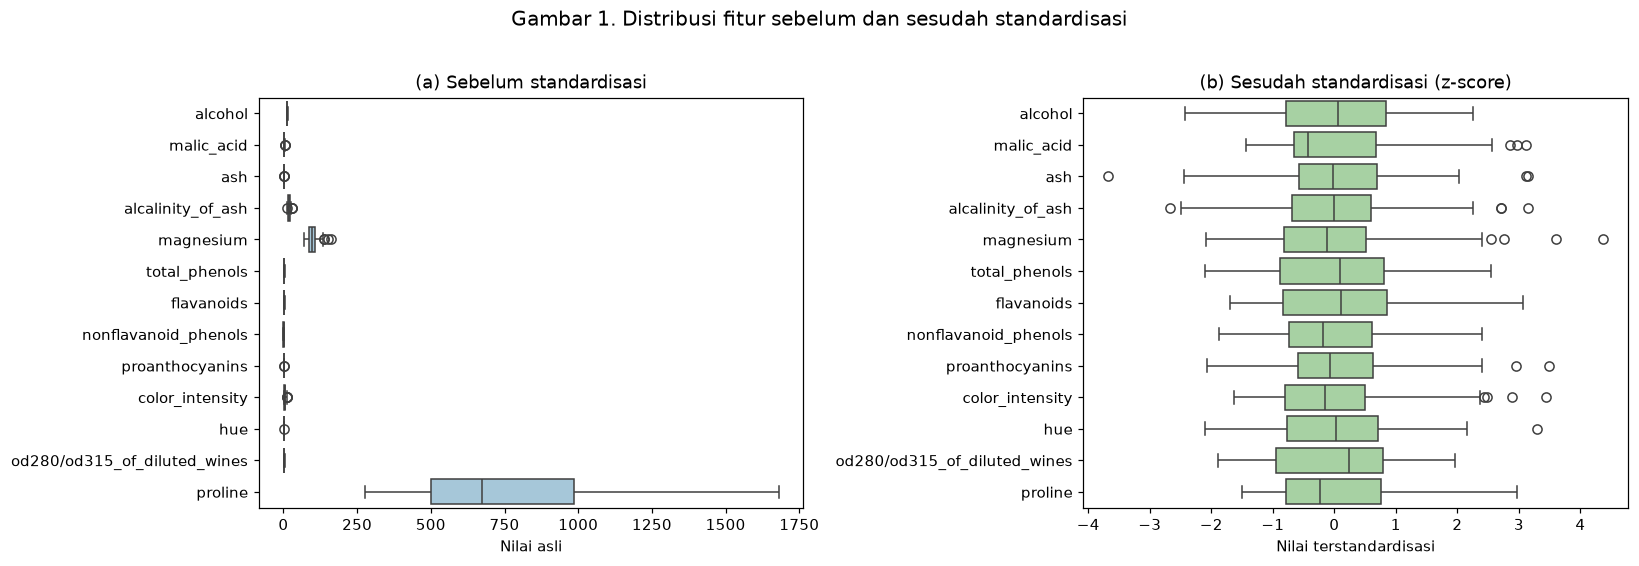

In [7]:
# Gambar 1. Boxplot sebelum dan sesudah standardisasi
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
sns.boxplot(data=X, orient="h", ax=ax[0], color="#9ecae1")
ax[0].set_title("(a) Sebelum standardisasi"); ax[0].set_xlabel("Nilai asli")
sns.boxplot(data=Xs_df, orient="h", ax=ax[1], color="#a1d99b")
ax[1].set_title("(b) Sesudah standardisasi (z-score)"); ax[1].set_xlabel("Nilai terstandardisasi")
fig.suptitle("Gambar 1. Distribusi fitur sebelum dan sesudah standardisasi", y=1.02, fontsize=13)
plt.tight_layout(); plt.show()

**Pembahasan Gambar 1 dan Tabel 2-3.** Sebelum standardisasi, skala fitur sangat timpang: `proline` memiliki rata-rata 746,9 dan simpangan baku 314,9 (rentang 278 sampai 1680), sedangkan `hue` hanya memiliki rata-rata 0,957 dan simpangan baku 0,229. Varians `proline` lebih dari satu juta kali varians `hue`, sehingga pada jarak Euclidean `proline` akan mendominasi. Setelah z-score, semua fitur berpusat di 0 dengan simpangan baku sekitar 1 (tertulis 1,003 pada Tabel 3 karena `pandas.describe()` memakai pembagi n-1, sedangkan `StandardScaler` memakai n), dan boxplot berada pada skala yang sebanding.

## 3. Metodologi Singkat

**Self-Organizing Map (SOM).** SOM terdiri dari kisi neuron berukuran $m \times n$. Setiap neuron memiliki *vektor bobot* $\mathbf{w}_{ij}$ berdimensi sama dengan data (13 fitur). Untuk setiap data masukan $\mathbf{x}$, pelatihan berjalan sebagai berikut:

1. **Cari BMU (Best Matching Unit)**, yaitu neuron dengan bobot paling dekat ke $\mathbf{x}$: $\text{BMU} = \arg\min_{ij} \lVert \mathbf{x} - \mathbf{w}_{ij} \rVert$.
2. **Perbarui bobot** BMU dan tetangganya agar mendekati $\mathbf{x}$:
   $$\mathbf{w}_{ij}(t+1) = \mathbf{w}_{ij}(t) + \alpha(t)\, h_{ij}(t)\, \big(\mathbf{x} - \mathbf{w}_{ij}(t)\big)$$
   dengan fungsi tetangga Gaussian $h_{ij}(t) = \exp\!\big(-d_{ij}^2 / 2\sigma(t)^2\big)$, di mana $d_{ij}$ adalah jarak pada kisi antara neuron $(i,j)$ dan BMU.
3. Laju pembelajaran $\alpha(t)$ dan lebar tetangga $\sigma(t)$ **menurun** selama pelatihan (pada MiniSom: peluruhan asimtotik), sehingga peta berubah dari penataan global yang kasar menjadi penyesuaian lokal yang halus.

**K-Means** membagi data ke $K$ cluster dengan meminimalkan jumlah kuadrat jarak titik ke centroid-nya (*inertia*).

**Pendekatan SOM + K-Means.** (i) Latih SOM; (ii) ambil bobot neuron yang memenangkan minimal satu data sebagai prototipe; (iii) jalankan K-Means pada prototipe tersebut; (iv) label setiap observasi = cluster dari neuron BMU-nya.

**Pembanding.** K-Means langsung pada 178 observasi terstandardisasi dengan $K$ yang sama.

**Metrik evaluasi** (dihitung pada data terstandardisasi asli, bukan pada bobot neuron):
- *Silhouette Score* ∈ [-1, 1], semakin tinggi semakin baik.
- *Davies-Bouldin Index (DBI)* ≥ 0, semakin rendah semakin baik.
- Sebagai pelengkap interpretasi (bukan bagian ketentuan tugas): *Adjusted Rand Index (ARI)* terhadap kultivar sebenarnya dan *crosstab* cluster vs kultivar.

**Pustaka:** `MiniSom` (kelas `MiniSom`; fungsi `random_weights_init`, `train_random`, `winner`, `distance_map`, `activation_response`, `get_weights`, `quantization_error`, `topographic_error`), serta `scikit-learn` (`StandardScaler`, `KMeans`, `PCA`, `silhouette_score`, `davies_bouldin_score`, `adjusted_rand_score`).

## 4. Tahap 2: Implementasi Self-Organizing Map

### 4.1 Penentuan parameter

**Tabel 4. Konfigurasi SOM utama**

| Parameter | Nilai | Alasan |
|---|---|---|
| Ukuran grid | 8 × 8 (64 neuron) | Aturan praktis jumlah neuron ≈ 5√N = 5√178 ≈ 67. Grid 8×8 cukup detail namun tidak terlalu banyak neuron kosong |
| Epoch | 60 (≈ 10.680 iterasi) | Setiap iterasi MiniSom memproses satu sampel acak; 60 epoch × 178 sampel memberi cukup kesempatan bagi peta untuk konvergen |
| Learning rate awal α₀ | 0,5 | Nilai awal umum; meluruh selama pelatihan |
| Lebar tetangga awal σ₀ | 1,5 | Harus lebih kecil dari ukuran grid; 1,5 memberi pengaruh ke tetangga langsung tanpa meratakan seluruh peta |
| Fungsi tetangga | Gaussian | Pengaruh meluruh mulus terhadap jarak |
| Topologi | Persegi (rectangular) | Default MiniSom, mudah divisualisasikan |
| Inisialisasi bobot | `random_weights_init` (sampel acak) | Bobot awal berada di rentang data |
| Seed | 42 | Reprodusibilitas |

In [8]:
# ---- Parameter SOM utama ----
GRID_X, GRID_Y = 8, 8
SIGMA, LR = 1.5, 0.5
EPOCHS = 60
N_ITER = EPOCHS * len(Xs)          # jumlah iterasi total
K = 3                              # jumlah cluster (dijustifikasi di Tahap 3)

# ---- Fungsi bantu (dipakai di seluruh notebook) ----
def train_som(gx, gy, sigma=SIGMA, lr=LR, epochs=EPOCHS, seed=SEED, data=Xs):
    """Latih SOM dengan MiniSom dan kembalikan objek SOM."""
    som = MiniSom(gx, gy, data.shape[1], sigma=sigma, learning_rate=lr,
                  neighborhood_function="gaussian", topology="rectangular",
                  random_seed=seed)
    som.random_weights_init(data)
    som.train_random(data, epochs * len(data))
    return som

def get_bmus(som, data=Xs):
    """Koordinat BMU (baris, kolom) untuk setiap observasi."""
    return np.array([som.winner(x) for x in data])

def order_clusters(labels, ref=X["proline"].values):
    """Urutkan label cluster berdasarkan rata-rata proline (besar -> kecil) agar
    warna/nomor cluster konsisten antarpendekatan. Mengembalikan dict pemetaan lama->baru."""
    ids = np.unique(labels)
    urut = sorted(ids, key=lambda c: -ref[labels == c].mean())
    return {old: new for new, old in enumerate(urut)}

def som_kmeans(som, k=K, data=Xs, seed=SEED):
    """Tahap 3: K-Means pada bobot neuron aktif (menang >= 1 data); label data via BMU."""
    gx, gy = som.get_weights().shape[:2]
    bmus = get_bmus(som, data)
    hit = som.activation_response(data)
    aktif = np.argwhere(hit > 0)                               # koordinat neuron aktif
    W = som.get_weights()[aktif[:, 0], aktif[:, 1]]            # bobot neuron aktif (prototipe)
    km = KMeans(n_clusters=k, n_init=10, random_state=seed).fit(W)
    neuron_lab = np.full((gx, gy), -1)
    neuron_lab[aktif[:, 0], aktif[:, 1]] = km.labels_
    labels = neuron_lab[bmus[:, 0], bmus[:, 1]]                # warisi label dari BMU
    mp = order_clusters(labels)                                # samakan penomoran cluster
    labels = np.array([mp[l] for l in labels])
    neuron_lab = np.where(neuron_lab >= 0, np.vectorize(lambda l: mp.get(l, -1))(neuron_lab), -1)
    return dict(som=som, bmus=bmus, hit=hit, aktif=aktif, W=W, km=km,
                neuron_lab=neuron_lab, labels=labels)

def metrik(labels, data=Xs):
    return dict(Silhouette=silhouette_score(data, labels),
                DBI=davies_bouldin_score(data, labels),
                ARI=adjusted_rand_score(y, labels))

PALET = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd", "#8c564b"]

def plot_umatrix(ax, som, judul="U-Matrix"):
    im = ax.imshow(som.distance_map(), cmap="bone_r")
    ax.set_title(judul); ax.set_xlabel("Kolom neuron"); ax.set_ylabel("Baris neuron")
    return im

def plot_hitmap(ax, hit, judul="Peta jumlah data per neuron (hit map)"):
    im = ax.imshow(hit, cmap="YlOrRd")
    for i in range(hit.shape[0]):
        for j in range(hit.shape[1]):
            if hit[i, j] > 0:
                ax.text(j, i, int(hit[i, j]), ha="center", va="center", fontsize=7)
    ax.set_title(judul); ax.set_xlabel("Kolom neuron"); ax.set_ylabel("Baris neuron")
    return im

def plot_cluster_map(ax, neuron_lab, hit, judul="Peta cluster SOM + K-Means"):
    k = neuron_lab.max() + 1
    cmap = ListedColormap(PALET[:k]); cmap.set_bad("#e5e5e5")
    ax.imshow(np.ma.masked_where(neuron_lab < 0, neuron_lab), cmap=cmap, vmin=-0.5, vmax=k - 0.5)
    for i in range(hit.shape[0]):
        for j in range(hit.shape[1]):
            if hit[i, j] > 0:
                ax.text(j, i, int(hit[i, j]), ha="center", va="center", fontsize=7, color="white", fontweight="bold")
    ax.set_title(judul); ax.set_xlabel("Kolom neuron"); ax.set_ylabel("Baris neuron")

# PCA 2D hanya untuk visualisasi ruang fitur
pca = PCA(n_components=2, random_state=SEED).fit(Xs)
Z = pca.transform(Xs)
def plot_pca(ax, labels, judul):
    for c in np.unique(labels):
        ax.scatter(Z[labels == c, 0], Z[labels == c, 1], s=28, color=PALET[c], label=f"Cluster {c}", edgecolor="white", linewidth=0.4)
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
    ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
    ax.set_title(judul); ax.legend(fontsize=8)

print(f"Iterasi total = {EPOCHS} epoch x {len(Xs)} sampel = {N_ITER}")
print(f"Total varians dijelaskan PC1+PC2: {pca.explained_variance_ratio_.sum()*100:.1f}%")

Iterasi total = 60 epoch x 178 sampel = 10680
Total varians dijelaskan PC1+PC2: 55.4%


### 4.2 Pelatihan SOM

In [9]:
som = train_som(GRID_X, GRID_Y)
bmus = get_bmus(som)
hit = som.activation_response(Xs)

print(f"Quantization error : {som.quantization_error(Xs):.4f}  (rata-rata jarak data ke BMU-nya; makin kecil makin baik)")
print(f"Topographic error  : {som.topographic_error(Xs):.4f}  (proporsi data yang BMU pertama & keduanya tidak bertetangga; makin kecil makin baik)")
print(f"Neuron aktif (menang >=1 data): {int((hit>0).sum())} dari {GRID_X*GRID_Y}")
print(f"Neuron kosong                 : {int((hit==0).sum())}")

Quantization error : 1.4209  (rata-rata jarak data ke BMU-nya; makin kecil makin baik)
Topographic error  : 0.1180  (proporsi data yang BMU pertama & keduanya tidak bertetangga; makin kecil makin baik)
Neuron aktif (menang >=1 data): 63 dari 64
Neuron kosong                 : 1


### 4.3 Visualisasi peta SOM

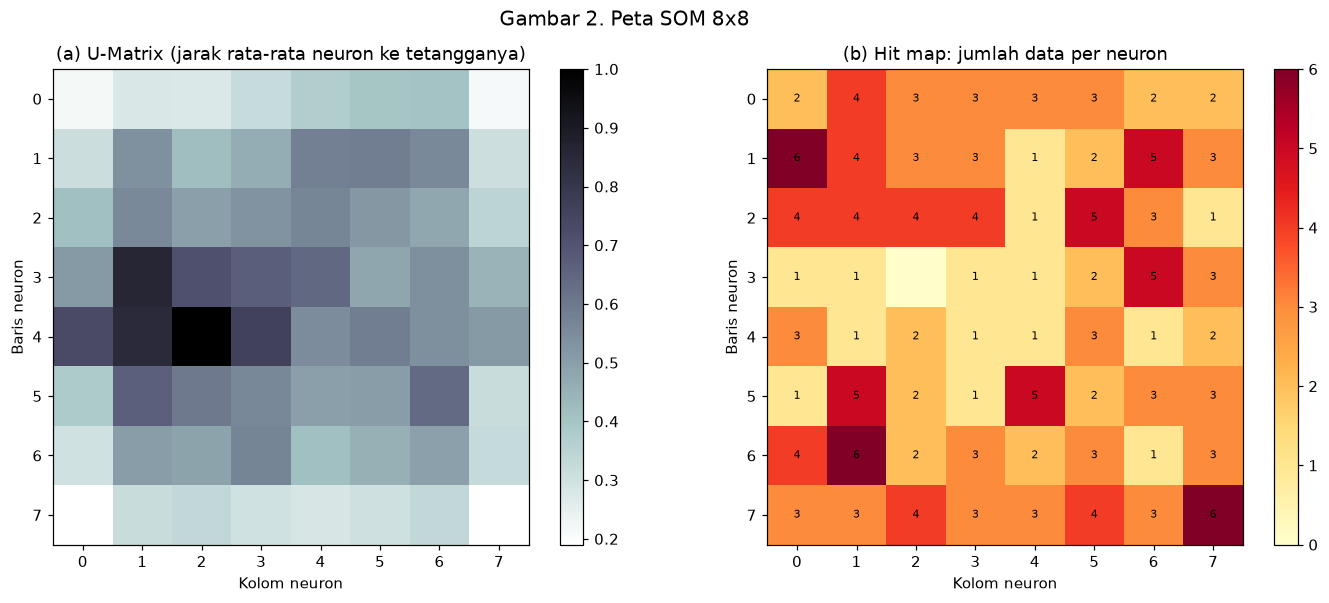

In [10]:
# Gambar 2. U-Matrix dan hit map
fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))
im0 = plot_umatrix(ax[0], som, "(a) U-Matrix (jarak rata-rata neuron ke tetangganya)")
plt.colorbar(im0, ax=ax[0], fraction=0.046)
im1 = plot_hitmap(ax[1], hit, "(b) Hit map: jumlah data per neuron")
plt.colorbar(im1, ax=ax[1], fraction=0.046)
fig.suptitle("Gambar 2. Peta SOM 8x8", fontsize=13); plt.tight_layout(); plt.show()

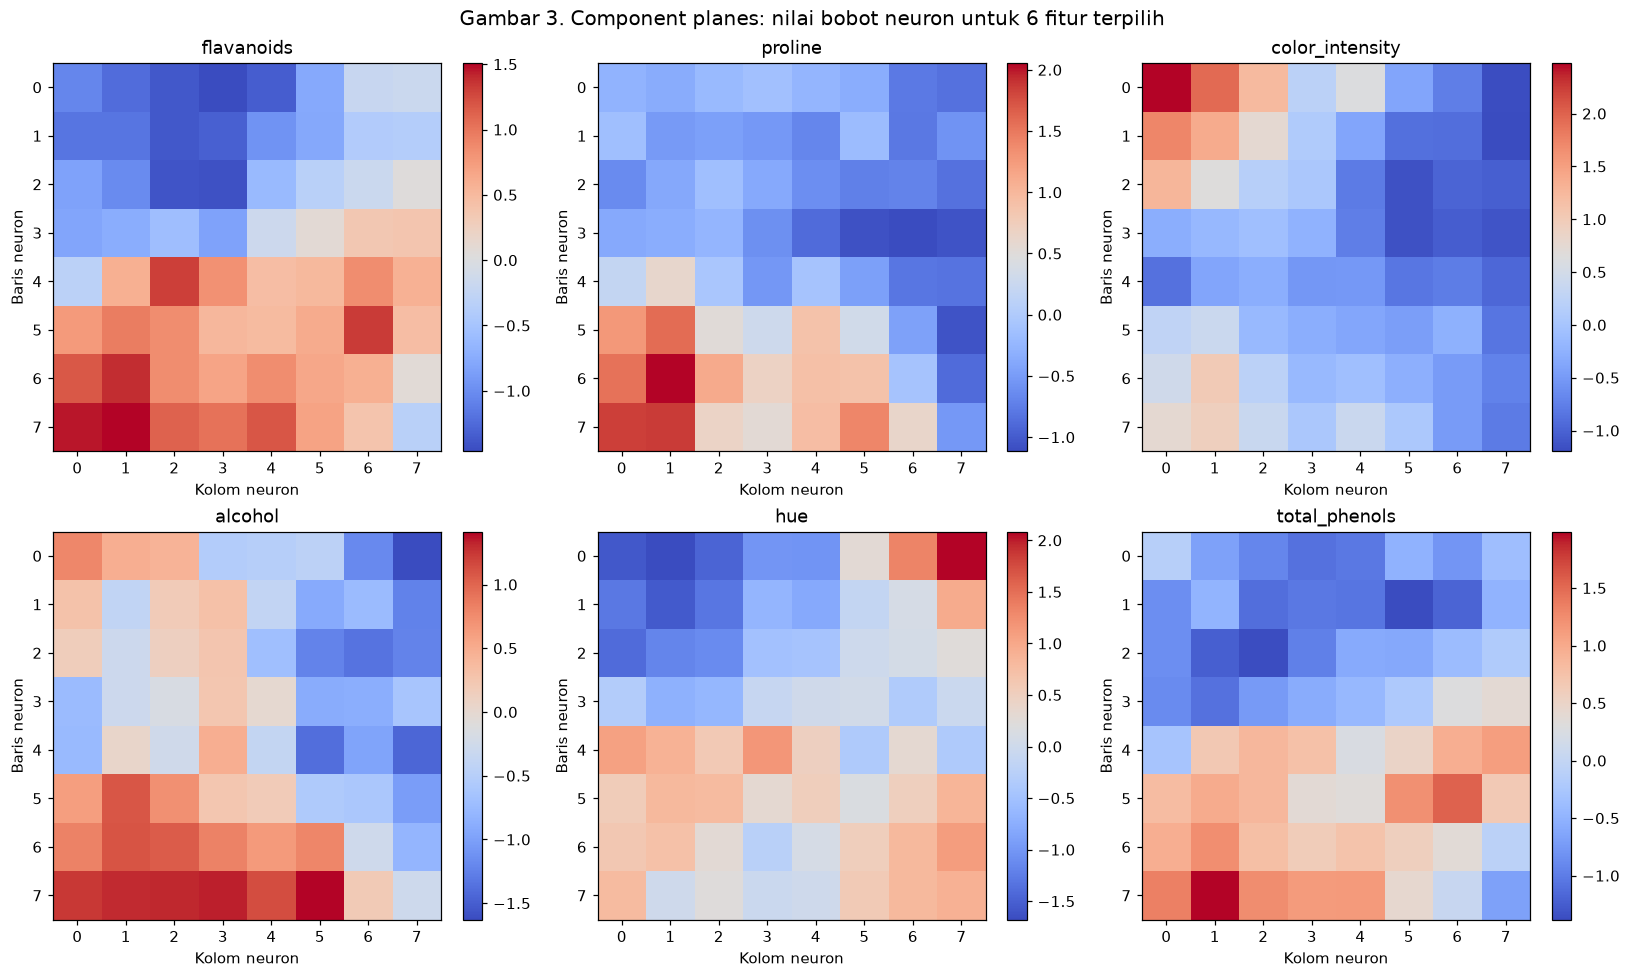

In [11]:
# Gambar 3. Component planes (visualisasi bobot per fitur, dalam satuan z-score)
W = som.get_weights()
pilih = ["flavanoids", "proline", "color_intensity", "alcohol", "hue", "total_phenols"]
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for a, f in zip(axes.ravel(), pilih):
    im = a.imshow(W[:, :, FEATURES.index(f)], cmap="coolwarm")
    a.set_title(f); a.set_xlabel("Kolom neuron"); a.set_ylabel("Baris neuron")
    plt.colorbar(im, ax=a, fraction=0.046)
fig.suptitle("Gambar 3. Component planes: nilai bobot neuron untuk 6 fitur terpilih", fontsize=13)
plt.tight_layout(); plt.show()

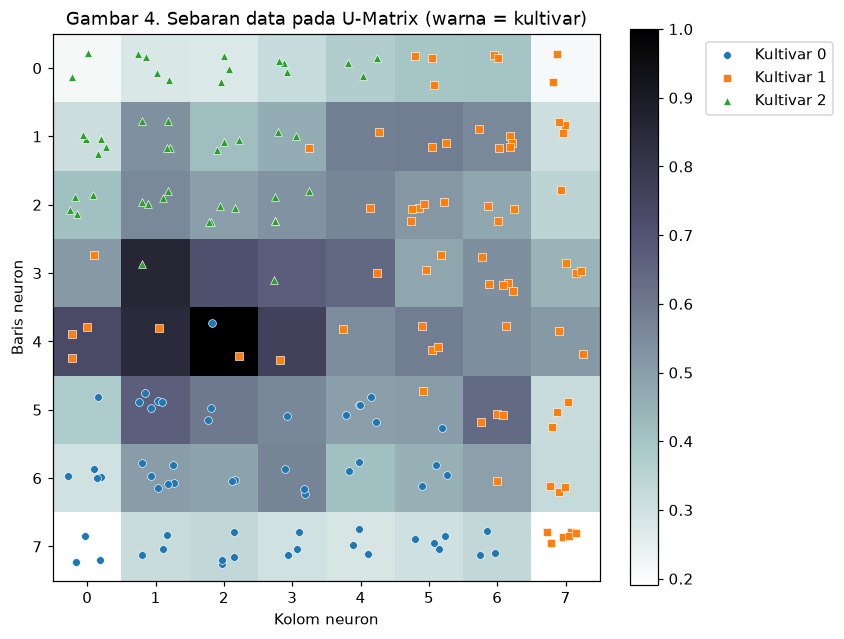

In [12]:
# Gambar 4. Posisi data pada U-Matrix, diwarnai kultivar (HANYA untuk interpretasi, label tidak dipakai melatih)
rng = np.random.default_rng(SEED)
fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = plot_umatrix(ax, som, "Gambar 4. Sebaran data pada U-Matrix (warna = kultivar)")
for c, mk in zip([0, 1, 2], ["o", "s", "^"]):
    idx = y == c
    ax.scatter(bmus[idx, 1] + rng.uniform(-.28, .28, idx.sum()), bmus[idx, 0] + rng.uniform(-.28, .28, idx.sum()),
               s=26, marker=mk, color=PALET[c], edgecolor="white", linewidth=.4, label=f"Kultivar {c}")
ax.legend(loc="upper left", bbox_to_anchor=(1.18, 1)); plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout(); plt.show()

### 4.4 Memahami BMU

In [13]:
# Demonstrasi BMU untuk satu observasi: hitung manual dan bandingkan dengan som.winner()
idx = 0
x = Xs[idx]
Wf = som.get_weights()
jarak = np.linalg.norm(Wf - x, axis=2)               # jarak x ke bobot SEMUA neuron
bmu_manual = np.unravel_index(jarak.argmin(), jarak.shape)
print(f"Observasi ke-{idx}")
print(f"  BMU (hitung manual argmin) : {tuple(int(v) for v in bmu_manual)}")
print(f"  BMU (som.winner)           : {tuple(int(v) for v in som.winner(x))}")
print(f"  Jarak ke BMU               : {jarak.min():.4f}")
print(f"  Jarak rata-rata ke semua neuron: {jarak.mean():.4f}")
print(f"  Cocok untuk seluruh {len(Xs)} observasi?",
      all(tuple(np.unravel_index(np.linalg.norm(Wf - xi, axis=2).argmin(), (GRID_X, GRID_Y))) == tuple(b) for xi, b in zip(Xs, bmus)))

Observasi ke-0
  BMU (hitung manual argmin) : (7, 2)
  BMU (som.winner)           : (7, 2)
  Jarak ke BMU               : 1.0783
  Jarak rata-rata ke semua neuron: 4.7349
  Cocok untuk seluruh 178 observasi? True


**Pembahasan Gambar 2-4.**

*Kualitas peta.* Quantization error 1,42 berarti rata-rata jarak sebuah observasi ke BMU-nya sekitar 1,4 satuan simpangan baku pada ruang 13 dimensi. Topographic error 0,118 berarti sekitar 12% observasi memiliki BMU pertama dan kedua yang tidak bertetangga. Peta cukup baik mempertahankan topologi, tetapi tidak sempurna. Sebanyak 63 dari 64 neuron memperoleh minimal satu data, dengan 1 sampai 6 data per neuron (Gambar 2b).

*U-Matrix (Gambar 2a).* Terdapat **punggungan gelap (jarak antarneuron besar)** di sekitar baris 3-4, kolom 0-3, dengan puncak di neuron (4, 2). Wilayah gelap menandakan neuron bertetangga yang bobotnya berjauhan, sehingga berfungsi sebagai **batas antarkelompok**. Wilayah terang (misalnya baris 0 dan baris 7) adalah area dengan bobot yang rapat, yaitu kelompok yang homogen. Punggungan itu memisahkan bagian atas peta dari bagian bawah.

*Component planes (Gambar 3).* Bagian bawah peta (baris 4-7) memiliki `flavanoids`, `total_phenols`, dan `alcohol` tinggi. `proline` tinggi terkonsentrasi di kiri bawah. Sudut kiri atas memiliki `color_intensity` tinggi dengan `flavanoids` rendah. Dengan demikian peta tersusun oleh gradasi sifat kimia, bukan acak.

*Sebaran data (Gambar 4).* Setelah warna kultivar ditumpangkan (label tidak dipakai saat pelatihan), Kultivar 2 menempati kiri atas, Kultivar 0 menempati bagian bawah, dan Kultivar 1 tersebar di sisi kanan. Beberapa titik Kultivar 1 muncul di dekat punggungan gelap (kolom 0-3, baris 3-4), yang menunjukkan wilayah tumpang tindih dengan kelompok lain.

*BMU.* Demonstrasi pada observasi ke-0 menunjukkan BMU hasil `argmin` manual identik dengan `som.winner()`, dan hal yang sama berlaku untuk seluruh 178 observasi. BMU inilah yang menentukan posisi sebuah data pada peta dan, pada Tahap 3, menentukan label cluster-nya.

## 5. Tahap 3: Clustering SOM + K-Means

### 5.1 Penentuan jumlah cluster K
K ditentukan dengan metode *elbow* (inertia) dan Silhouette pada **bobot neuron aktif**. Sebagai pembanding, Silhouette K-Means langsung pada data juga ditampilkan.

Jumlah prototipe (neuron aktif): 63  | dimensi bobot: 13


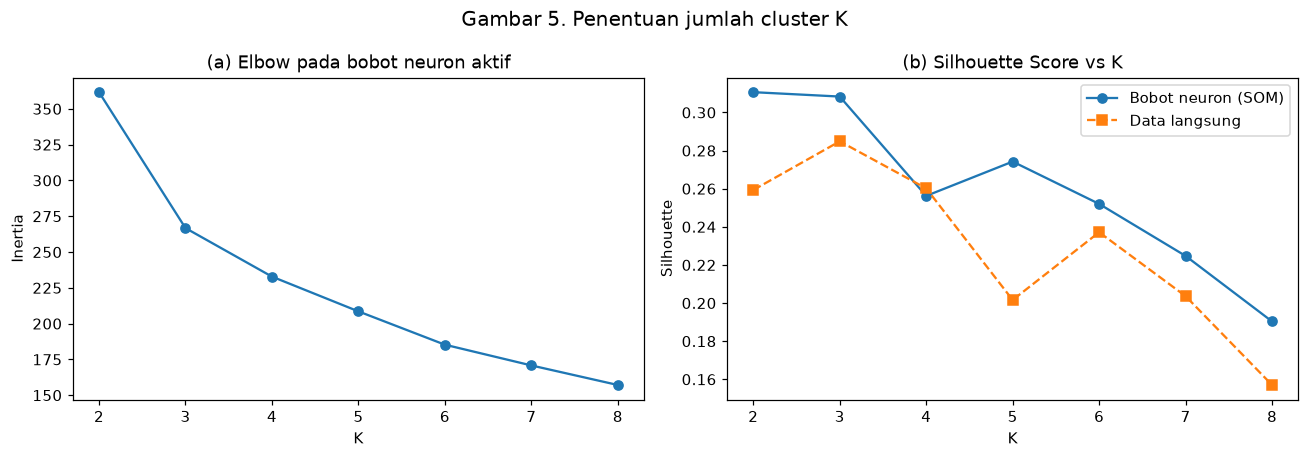

,K,Inertia (bobot),Silhouette (bobot),Silhouette (data langsung)
0,2,361.655,0.311,0.259
1,3,266.730,0.308,0.285
2,4,232.829,0.256,0.260
3,5,208.555,0.274,0.202
4,6,185.286,0.252,0.237
5,7,170.798,0.225,0.204
6,8,157.137,0.190,0.157


In [14]:
aktif = np.argwhere(hit > 0)
Wa = som.get_weights()[aktif[:, 0], aktif[:, 1]]       # prototipe: bobot neuron yang menang >= 1 data
print(f"Jumlah prototipe (neuron aktif): {len(Wa)}  | dimensi bobot: {Wa.shape[1]}")

rentang = range(2, 9)
inertia, sil_w, sil_d = [], [], []
for k in rentang:
    kmw = KMeans(k, n_init=10, random_state=SEED).fit(Wa)
    inertia.append(kmw.inertia_); sil_w.append(silhouette_score(Wa, kmw.labels_))
    kmd = KMeans(k, n_init=10, random_state=SEED).fit(Xs)
    sil_d.append(silhouette_score(Xs, kmd.labels_))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].plot(list(rentang), inertia, "o-"); ax[0].set_title("(a) Elbow pada bobot neuron aktif")
ax[0].set_xlabel("K"); ax[0].set_ylabel("Inertia")
ax[1].plot(list(rentang), sil_w, "o-", label="Bobot neuron (SOM)")
ax[1].plot(list(rentang), sil_d, "s--", label="Data langsung")
ax[1].set_title("(b) Silhouette Score vs K"); ax[1].set_xlabel("K"); ax[1].set_ylabel("Silhouette"); ax[1].legend()
fig.suptitle("Gambar 5. Penentuan jumlah cluster K", fontsize=13); plt.tight_layout(); plt.show()
pd.DataFrame({"K": list(rentang), "Inertia (bobot)": inertia, "Silhouette (bobot)": sil_w, "Silhouette (data langsung)": sil_d}).round(4)

**Pembahasan Gambar 5.** Kurva *elbow* pada bobot neuron aktif menurun tajam dari K=2 ke K=3 (inertia 361,7 menjadi 266,7, selisih sekitar 95), lalu melandai (K=3 ke K=4: 266,7 menjadi 232,8, selisih sekitar 34), sehingga tekukan terlihat di **K = 3**. Silhouette pada bobot neuron untuk K=2 (0,311) dan K=3 (0,308) hampir sama, sedangkan pada K-Means langsung nilai tertinggi ada di K=3 (0,285). Selain itu, dataset ini berasal dari 3 kultivar, sehingga K=3 masuk akal secara konteks. **K = 3 dipakai untuk kedua pendekatan.** Perlu dicatat bahwa K=2 secara metrik hampir setara pada bobot neuron, sehingga pemilihan K=3 juga bertumpu pada konteks, tidak semata pada metrik.

### 5.2 Menjalankan SOM + K-Means dan memberi label via BMU

In [15]:
res = som_kmeans(som, k=K)
lab_som = res["labels"]
print(f"K-Means dijalankan pada {len(res['W'])} bobot neuron aktif (bukan pada 64 neuron, bukan pada koordinat grid).")
print("Ukuran cluster (jumlah observasi):", {int(a): int(b) for a, b in zip(*np.unique(lab_som, return_counts=True))})
print("Contoh label 5 observasi pertama:")
pd.DataFrame({"obs": range(5), "BMU(baris,kolom)": [tuple(int(v) for v in b) for b in res["bmus"][:5]], "cluster": lab_som[:5]})

K-Means dijalankan pada 63 bobot neuron aktif (bukan pada 64 neuron, bukan pada koordinat grid).
Ukuran cluster (jumlah observasi): {0: 66, 1: 54, 2: 58}
Contoh label 5 observasi pertama:


,obs,"BMU(baris,kolom)",cluster
0,0,"(7, 2)",0
1,1,"(7, 6)",0
2,2,"(6, 0)",0
3,3,"(7, 1)",0
4,4,"(5, 2)",0


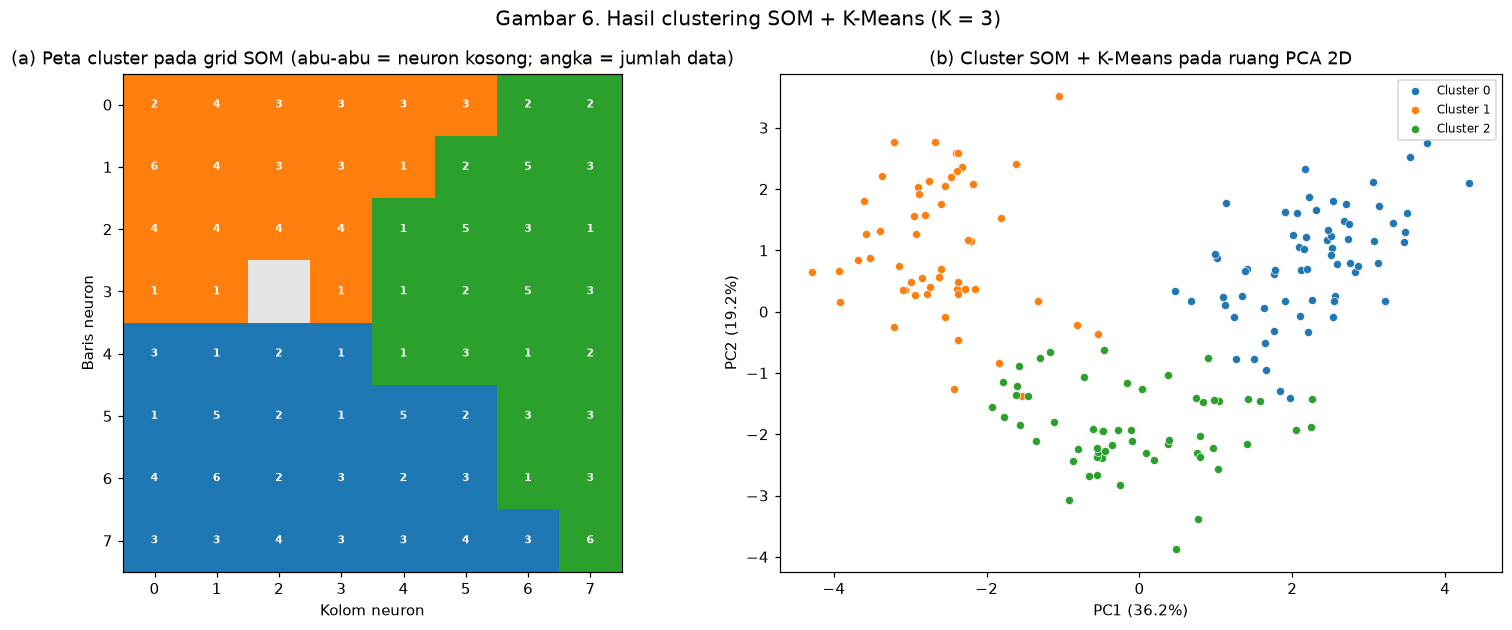

In [16]:
# Gambar 6. Hasil SOM + K-Means pada peta SOM dan ruang fitur (PCA)
fig, ax = plt.subplots(1, 2, figsize=(14, 5.8))
plot_cluster_map(ax[0], res["neuron_lab"], res["hit"], "(a) Peta cluster pada grid SOM (abu-abu = neuron kosong; angka = jumlah data)")
plot_pca(ax[1], lab_som, "(b) Cluster SOM + K-Means pada ruang PCA 2D")
fig.suptitle("Gambar 6. Hasil clustering SOM + K-Means (K = 3)", fontsize=13); plt.tight_layout(); plt.show()

In [17]:
# Tabel 5. Profil cluster SOM + K-Means (rata-rata fitur pada satuan ASLI)
profil_som = X.assign(cluster=lab_som).groupby("cluster").mean()
profil_som.insert(0, "n", pd.Series(lab_som).value_counts().sort_index())
print("Tabel 5. Profil rata-rata fitur tiap cluster (SOM + K-Means)")
profil_som.T

Tabel 5. Profil rata-rata fitur tiap cluster (SOM + K-Means)


cluster,0,1,2
n,66.000,54.000,58.000
alcohol,13.611,13.099,12.215
malic_acid,1.949,3.201,1.972
ash,2.448,2.420,2.224
alcalinity_of_ash,17.580,21.070,20.207
magnesium,108.606,99.574,89.810
total_phenols,2.828,1.705,2.239
flavanoids,2.944,0.836,2.099
nonflavanoid_phenols,0.287,0.451,0.364
proanthocyanins,1.939,1.126,1.628


**Pembahasan Gambar 6 dan Tabel 5.** K-Means dijalankan pada 63 bobot neuron aktif, lalu setiap observasi mewarisi cluster dari BMU-nya. Cluster yang terbentuk menempati **wilayah yang bersambung pada peta** (Gambar 6a), sesuai sifat SOM bahwa neuron berdekatan memiliki bobot mirip. Penomoran cluster diurutkan berdasarkan rata-rata `proline` (menurun) agar konsisten dengan pendekatan lain.

- **Cluster 0 (66 data)**: `proline` tinggi (rata-rata 1075), `flavanoids` tinggi (2,94), `alcohol` tinggi (13,6). Berada di bagian bawah peta.
- **Cluster 1 (54 data)**: `color_intensity` tinggi (7,0), `flavanoids` rendah (0,84), `hue` rendah (0,71), `malic_acid` tinggi (3,2). Berada di kiri atas peta.
- **Cluster 2 (58 data)**: `proline` terendah (489), `alcohol` terendah (12,2), `color_intensity` rendah (2,96). Berada di sisi kanan peta.

Pada ruang PCA 2D (Gambar 6b), ketiga cluster terpisah cukup jelas, dengan sedikit tumpang tindih di perbatasan Cluster 1 dan 2. Perlu diingat PCA dua komponen hanya menjelaskan 55,4% varians, sehingga sebagian pemisahan tidak terlihat pada gambar.

## 6. Tahap 4: Pembanding, K-Means pada Data Asli
K-Means diterapkan langsung pada 178 observasi terstandardisasi dengan **K yang sama (K = 3)**, `n_init=10`, dan `random_state=42`.

Ukuran cluster: {0: 62, 1: 51, 2: 65}


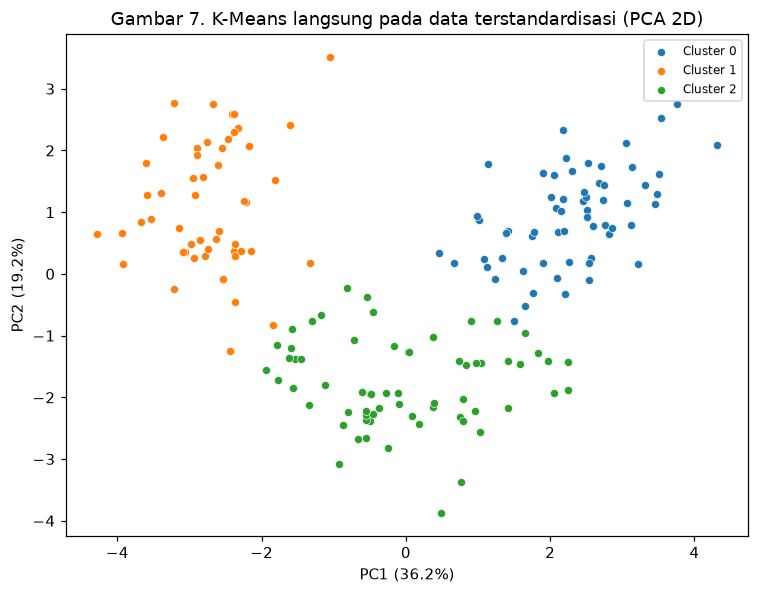

Tabel 6. Profil rata-rata fitur tiap cluster (K-Means langsung)


cluster,0,1,2
n,62.000,51.000,65.000
alcohol,13.677,13.134,12.251
malic_acid,1.998,3.307,1.897
ash,2.466,2.418,2.231
alcalinity_of_ash,17.463,21.241,20.063
magnesium,107.968,98.667,92.738
total_phenols,2.848,1.684,2.248
flavanoids,3.003,0.819,2.050
nonflavanoid_phenols,0.292,0.452,0.358
proanthocyanins,1.922,1.146,1.624


In [18]:
km_direct = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit(Xs)
mp = order_clusters(km_direct.labels_)
lab_km = np.array([mp[l] for l in km_direct.labels_])      # penomoran cluster disamakan (urut proline)

print("Ukuran cluster:", {int(a): int(b) for a, b in zip(*np.unique(lab_km, return_counts=True))})

fig, ax = plt.subplots(figsize=(7, 5.5))
plot_pca(ax, lab_km, "Gambar 7. K-Means langsung pada data terstandardisasi (PCA 2D)")
plt.tight_layout(); plt.show()

profil_km = X.assign(cluster=lab_km).groupby("cluster").mean()
profil_km.insert(0, "n", pd.Series(lab_km).value_counts().sort_index())
print("Tabel 6. Profil rata-rata fitur tiap cluster (K-Means langsung)")
profil_km.T

**Pembahasan Gambar 7 dan Tabel 6.** K-Means langsung menghasilkan tiga cluster dengan ukuran 62, 51, dan 65 serta profil yang **sangat mirip** dengan SOM + K-Means: Cluster 0 kaya `proline` dan `flavanoids` (rata-rata `proline` 1100), Cluster 1 memiliki `color_intensity` tinggi (7,2) dengan `flavanoids` rendah (0,82), dan Cluster 2 memiliki `proline` terendah (510) dan `alcohol` terendah (12,3). Perbedaan hanya terletak pada sejumlah titik di perbatasan antar cluster.

## 7. Tahap 5: Evaluasi dan Diskusi
Seluruh metrik dihitung pada **data observasi asli yang terstandardisasi** (`Xs`, 178 × 13), memakai label cluster dari masing-masing pendekatan.

In [19]:
hasil = pd.DataFrame({
    "SOM + K-Means": metrik(lab_som),
    "K-Means langsung": metrik(lab_km),
}).T
hasil["Ukuran cluster"] = [
    str(np.bincount(lab_som).tolist()), str(np.bincount(lab_km).tolist())]
print("Tabel 7. Perbandingan metrik evaluasi (Silhouette: lebih tinggi lebih baik; DBI: lebih rendah lebih baik;")
print("          ARI hanya pelengkap interpretasi terhadap kultivar, bukan bagian ketentuan tugas)")
hasil.round(4)

Tabel 7. Perbandingan metrik evaluasi (Silhouette: lebih tinggi lebih baik; DBI: lebih rendah lebih baik;
          ARI hanya pelengkap interpretasi terhadap kultivar, bukan bagian ketentuan tugas)


,Silhouette,DBI,ARI,Ukuran cluster
SOM + K-Means,0.278,1.382,0.787,"[66, 54, 58]"
K-Means langsung,0.285,1.389,0.897,"[62, 51, 65]"


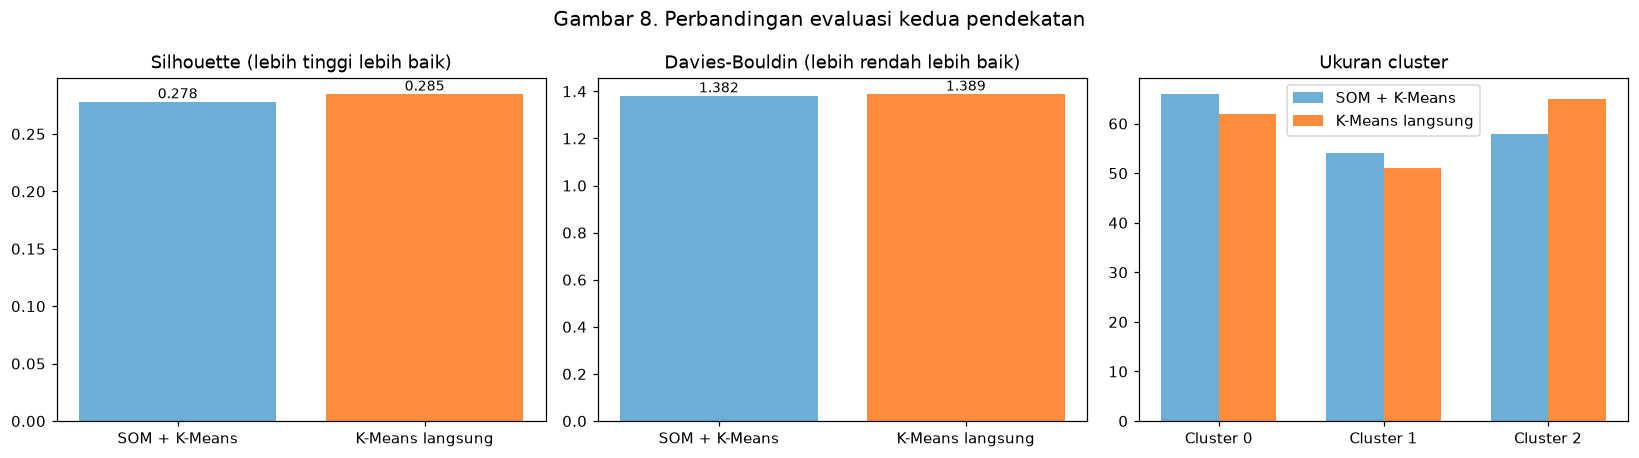

In [20]:
# Gambar 8. Perbandingan metrik dan ukuran cluster
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
nama = ["SOM + K-Means", "K-Means langsung"]
ax[0].bar(nama, hasil["Silhouette"], color=["#6baed6", "#fd8d3c"]); ax[0].set_title("Silhouette (lebih tinggi lebih baik)")
ax[1].bar(nama, hasil["DBI"], color=["#6baed6", "#fd8d3c"]); ax[1].set_title("Davies-Bouldin (lebih rendah lebih baik)")
w = 0.35; xx = np.arange(K)
ax[2].bar(xx - w/2, np.bincount(lab_som), w, label="SOM + K-Means", color="#6baed6")
ax[2].bar(xx + w/2, np.bincount(lab_km), w, label="K-Means langsung", color="#fd8d3c")
ax[2].set_xticks(xx); ax[2].set_xticklabels([f"Cluster {i}" for i in xx]); ax[2].set_title("Ukuran cluster"); ax[2].legend()
for a in ax[:2]:
    for p in a.patches: a.annotate(f"{p.get_height():.3f}", (p.get_x()+p.get_width()/2, p.get_height()), ha="center", va="bottom", fontsize=9)
fig.suptitle("Gambar 8. Perbandingan evaluasi kedua pendekatan", fontsize=13); plt.tight_layout(); plt.show()

Tabel 8. Crosstab SOM + K-Means


Kultivar,Kultivar 0,Kultivar 1,Kultivar 2
Cluster,,,
0,59,7,0
1,0,6,48
2,0,58,0


Tabel 9. Crosstab K-Means langsung


Kultivar,Kultivar 0,Kultivar 1,Kultivar 2
Cluster,,,
0,59,3,0
1,0,3,48
2,0,65,0


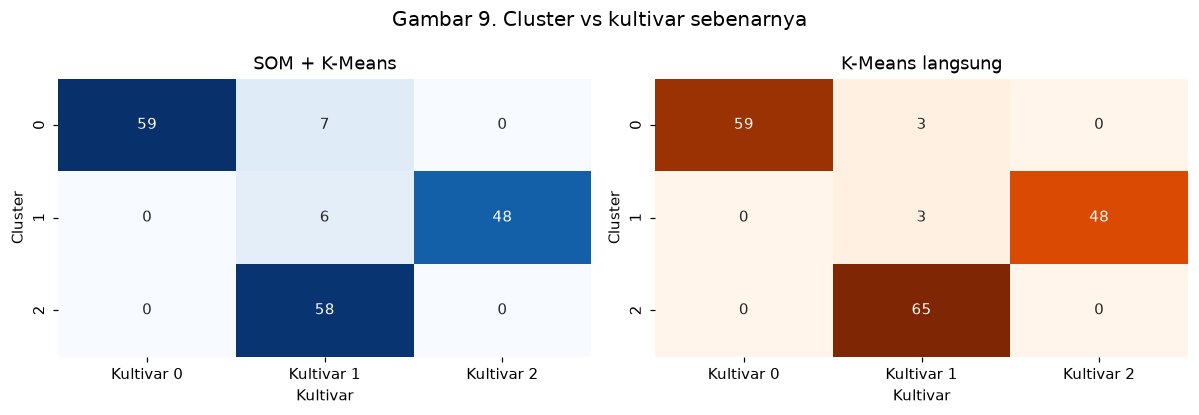

Jumlah observasi dengan label berbeda antara kedua pendekatan: 7 dari 178


In [21]:
# Tabel 8-9. Crosstab cluster vs kultivar sebenarnya (hanya untuk interpretasi)
nama_kultivar = {0: "Kultivar 0", 1: "Kultivar 1", 2: "Kultivar 2"}
ct_som = pd.crosstab(pd.Series(lab_som, name="Cluster"), pd.Series(y, name="Kultivar").map(nama_kultivar))
ct_km  = pd.crosstab(pd.Series(lab_km,  name="Cluster"), pd.Series(y, name="Kultivar").map(nama_kultivar))
print("Tabel 8. Crosstab SOM + K-Means"); display(ct_som)
print("Tabel 9. Crosstab K-Means langsung"); display(ct_km)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
sns.heatmap(ct_som, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax[0]); ax[0].set_title("SOM + K-Means")
sns.heatmap(ct_km,  annot=True, fmt="d", cmap="Oranges", cbar=False, ax=ax[1]); ax[1].set_title("K-Means langsung")
fig.suptitle("Gambar 9. Cluster vs kultivar sebenarnya", fontsize=13); plt.tight_layout(); plt.show()

# Pasangan data yang labelnya berbeda antar dua pendekatan
print("Jumlah observasi dengan label berbeda antara kedua pendekatan:", int((lab_som != lab_km).sum()), "dari", len(Xs))

**Pembahasan Tabel 7-9 dan Gambar 8-9.**

| Aspek | SOM + K-Means | K-Means langsung | Keterangan |
|---|---|---|---|
| Silhouette | 0,278 | 0,285 | K-Means langsung sedikit lebih tinggi |
| DBI | 1,382 | 1,389 | SOM + K-Means sedikit lebih rendah (lebih baik) |
| Ukuran cluster | 66 / 54 / 58 | 62 / 51 / 65 | Keduanya cukup seimbang |
| ARI terhadap kultivar (pelengkap) | 0,787 | 0,897 | K-Means langsung lebih cocok dengan kultivar |

**Perbandingan metrik.** Selisih kedua metrik sangat kecil (sekitar 0,007) dan **arahnya berlawanan**: Silhouette sedikit mengungguli K-Means langsung, sedangkan DBI sedikit mengungguli SOM + K-Means. Tidak ada pendekatan yang jelas lebih baik berdasarkan kedua metrik wajib.

**Ukuran cluster dan interpretasi.** Kedua pendekatan menghasilkan cluster berukuran seimbang dan profil kimia yang hampir identik. Hanya 7 dari 178 observasi yang labelnya berbeda antara kedua pendekatan.

**Perbandingan dengan kultivar (hanya sebagai bahan interpretasi).** Pada SOM + K-Means, 13 observasi (7,3%) berada pada cluster yang dominan kultivar lain (7 Kultivar 1 masuk Cluster 0 dan 6 Kultivar 1 masuk Cluster 1). Pada K-Means langsung hanya 6 observasi (3,4%). Artinya, untuk dataset ini K-Means langsung sedikit lebih sesuai dengan struktur kultivar yang sebenarnya. Perlu diingat ARI bukan bagian dari ketentuan tugas dan kultivar belum tentu merupakan struktur "benar" yang harus ditemukan clustering.

**Nilai Silhouette sekitar 0,28** menunjukkan struktur cluster yang sedang (tidak sangat tegas), konsisten dengan tumpang tindih Kultivar 1 dengan kelompok lain yang terlihat pada U-Matrix.

**Apakah SOM bermanfaat di sini?** Dari sisi metrik, tidak ada keunggulan. Dari sisi **visualisasi dan interpretasi**, SOM memberi nilai tambah: U-Matrix memperlihatkan batas kelompok, component planes menunjukkan fitur mana yang membedakan wilayah peta, dan hit map memperlihatkan kepadatan data. Informasi ini tidak tersedia dari K-Means langsung. Untuk dataset kecil dan bersih seperti Wine, manfaat SOM lebih bersifat eksploratif daripada peningkatan akurasi.

## 8. Eksperimen Tambahan: Pengaruh Ukuran Grid SOM

**Desain.** Ukuran grid dibandingkan: **5×5**, **8×8** (utama), dan **12×12**. Parameter lain dijaga tetap: σ₀ = 1,5; α₀ = 0,5; 60 epoch; seed 42; K = 3.

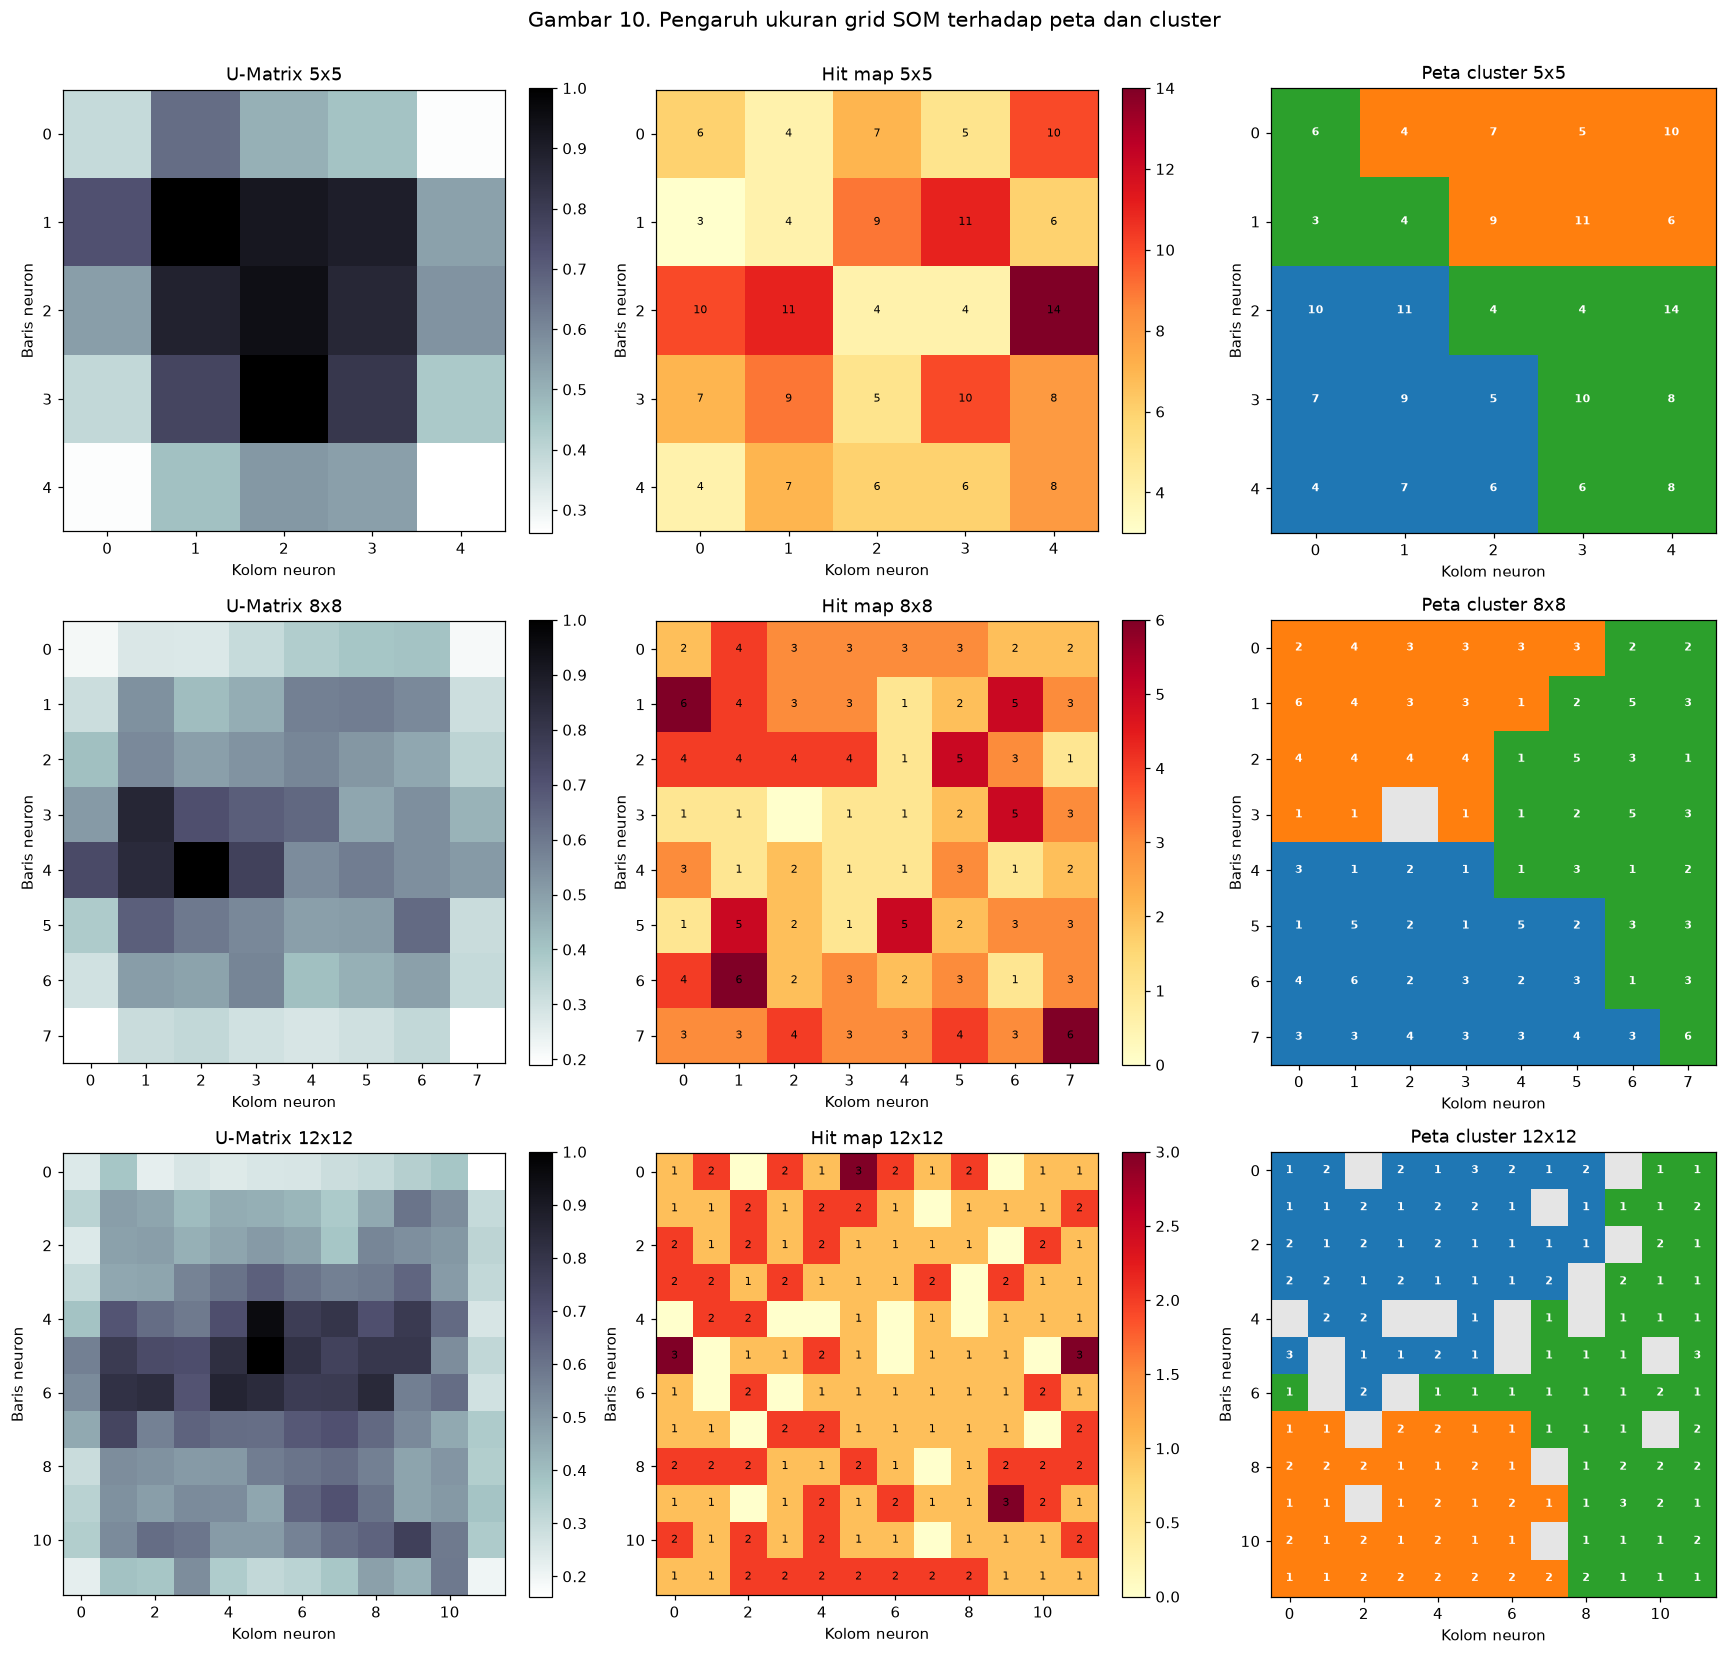

In [22]:
grids = [(5, 5), (8, 8), (12, 12)]
eksp = {}
for g in grids:
    s = train_som(*g)                      # parameter lain sama persis
    r = som_kmeans(s, k=K)
    eksp[g] = r

fig, axes = plt.subplots(3, 3, figsize=(16, 15))
for row, g in enumerate(grids):
    r = eksp[g]
    im = plot_umatrix(axes[row, 0], r["som"], f"U-Matrix {g[0]}x{g[1]}"); plt.colorbar(im, ax=axes[row, 0], fraction=0.046)
    im = plot_hitmap(axes[row, 1], r["hit"], f"Hit map {g[0]}x{g[1]}"); plt.colorbar(im, ax=axes[row, 1], fraction=0.046)
    plot_cluster_map(axes[row, 2], r["neuron_lab"], r["hit"], f"Peta cluster {g[0]}x{g[1]}")
fig.suptitle("Gambar 10. Pengaruh ukuran grid SOM terhadap peta dan cluster", fontsize=14, y=1.0)
plt.tight_layout(); plt.show()

In [23]:
baris = []
for g in grids:
    r = eksp[g]; s = r["som"]; m = metrik(r["labels"])
    baris.append({"Grid": f"{g[0]}x{g[1]}", "Neuron total": g[0]*g[1],
                  "Neuron aktif": len(r["aktif"]), "Neuron kosong": g[0]*g[1]-len(r["aktif"]),
                  "Rata-rata data/neuron aktif": round(len(Xs)/len(r["aktif"]), 2),
                  "Quantization err": s.quantization_error(Xs), "Topographic err": s.topographic_error(Xs),
                  "Silhouette": m["Silhouette"], "DBI": m["DBI"], "ARI": m["ARI"],
                  "Ukuran cluster": str(np.bincount(r["labels"]).tolist())})
baris.append({"Grid": "K-Means langsung (acuan)", "Neuron total": "-", "Neuron aktif": "-", "Neuron kosong": "-",
              "Rata-rata data/neuron aktif": "-", "Quantization err": np.nan, "Topographic err": np.nan,
              "Silhouette": hasil.loc["K-Means langsung", "Silhouette"], "DBI": hasil.loc["K-Means langsung", "DBI"],
              "ARI": hasil.loc["K-Means langsung", "ARI"], "Ukuran cluster": str(np.bincount(lab_km).tolist())})
tab_eksp = pd.DataFrame(baris).set_index("Grid")
print("Tabel 10. Hasil eksperimen ukuran grid (parameter lain tetap)")
tab_eksp

Tabel 10. Hasil eksperimen ukuran grid (parameter lain tetap)


,Neuron total,Neuron aktif,Neuron kosong,Rata-rata data/neuron aktif,Quantization err,Topographic err,Silhouette,DBI,ARI,Ukuran cluster
Grid,,,,,,,,,,
5x5,25,25,0,7.12,1.835,0.129,0.268,1.447,0.770,"[59, 52, 67]"
8x8,64,63,1,2.83,1.421,0.118,0.278,1.382,0.787,"[66, 54, 58]"
12x12,144,124,20,1.44,0.924,0.062,0.283,1.391,0.848,"[64, 52, 62]"
K-Means langsung (acuan),-,-,-,-,NaN,NaN,0.285,1.389,0.897,"[62, 51, 65]"


### Uji kestabilan terhadap inisialisasi acak (pelengkap)
SOM dan K-Means sama-sama bergantung pada inisialisasi acak. Agar kesimpulan tidak bertumpu pada satu seed, grid 8×8 dan K-Means langsung diulang dengan 10 seed berbeda.

In [24]:
rows = []
for sd in range(10):
    s = train_som(8, 8, seed=sd)
    r = som_kmeans(s, k=K, seed=sd)
    m1 = metrik(r["labels"])
    kmd = KMeans(K, n_init=10, random_state=sd).fit(Xs)
    m2 = metrik(kmd.labels_)
    rows.append({"seed": sd, "Sil SOM+KM": m1["Silhouette"], "DBI SOM+KM": m1["DBI"], "ARI SOM+KM": m1["ARI"],
                 "Sil KM": m2["Silhouette"], "DBI KM": m2["DBI"], "ARI KM": m2["ARI"]})
rob = pd.DataFrame(rows).set_index("seed")
ringkas = rob.agg(["mean", "std", "min", "max"]).T
print("Tabel 11. Ringkasan 10 seed (grid 8x8 untuk SOM)")
ringkas.round(4)

Tabel 11. Ringkasan 10 seed (grid 8x8 untuk SOM)


,mean,std,min,max
Sil SOM+KM,0.278,1.900e-03,0.276,0.281
DBI SOM+KM,1.398,1.390e-02,1.377,1.419
ARI SOM+KM,0.812,1.500e-02,0.788,0.846
Sil KM,0.285,3.000e-04,0.285,0.286
DBI KM,1.389,8.000e-04,1.389,1.392
ARI KM,0.899,5.500e-03,0.897,0.915


**Pembahasan Gambar 10, Tabel 10, dan Tabel 11.**

*Pengaruh ukuran grid terhadap peta.*
- **5×5 (25 neuron, rata-rata 7,1 data per neuron)**: tidak ada neuron kosong, peta kasar, dan satu neuron mewakili banyak data (hingga 14). Quantization error tertinggi (1,835). U-Matrix hanya menampilkan satu punggungan besar sehingga detail struktur hilang.
- **8×8 (64 neuron, 2,8 data per neuron)**: hampir semua neuron terisi (63 aktif), punggungan batas terlihat jelas, dan peta masih mudah dibaca. Quantization error 1,421.
- **12×12 (144 neuron, 1,4 data per neuron)**: 20 neuron kosong, banyak neuron hanya berisi 1-2 data, dan peta cluster tampak berbintik karena neuron kosong tersebar. Quantization error terendah (0,924) dan topographic error terendah (0,062), tetapi penurunan quantization error ini **wajar** karena prototipe lebih banyak, dan tidak otomatis berarti cluster lebih baik.

*Pengaruh terhadap hasil cluster dan metrik.* Silhouette naik tipis seiring membesarnya grid (0,268 → 0,278 → 0,283) dan mendekati K-Means langsung (0,285). DBI terbaik ada pada 8×8 (1,382), lalu 12×12 (1,391), dan terburuk pada 5×5 (1,447). ARI naik dari 0,770 ke 0,787 lalu 0,848. Pada grid yang lebih besar, prototipe lebih mendekati data aslinya sehingga hasilnya mendekati K-Means langsung. Pada grid kecil, setiap neuron merangkum banyak data dan sebagian batas cluster menjadi kurang tajam. Perubahan metrik antar grid relatif kecil dibanding perubahan tampilan peta, sehingga pengaruh terbesar ukuran grid ada pada **kualitas representasi visual**.

*Kestabilan terhadap seed (Tabel 11).* Dengan 10 seed berbeda, SOM + K-Means (8×8) memiliki Silhouette rata-rata 0,278 (rentang 0,276 sampai 0,281) dan DBI rata-rata 1,398 (rentang 1,377 sampai 1,419), sedangkan K-Means langsung memiliki Silhouette 0,285 (rentang 0,285 sampai 0,286) dan DBI 1,389 (rentang 1,389 sampai 1,392). Silhouette K-Means langsung lebih tinggi pada seluruh seed (maksimum SOM 0,281 masih di bawah minimum K-Means 0,285). Pada DBI, sebagian seed SOM lebih baik dan sebagian lebih buruk. K-Means langsung juga lebih stabil, sedangkan SOM + K-Means lebih bervariasi karena menambah satu sumber keacakan (inisialisasi dan urutan sampel SOM). Hasil seed 42 yang menampilkan DBI SOM sedikit lebih baik karenanya **tidak boleh digeneralisasi**.

## 9. Jawaban Pertanyaan Analisis

**1. Mengapa fitur perlu distandardisasi sebelum SOM dan K-Means?**
SOM (pencarian BMU) dan K-Means sama-sama bergantung pada jarak Euclidean. Tanpa standardisasi, fitur berskala besar mendominasi jarak. Pada data ini, `proline` (simpangan baku 314,9) memiliki varians lebih dari satu juta kali `hue` (simpangan baku 0,229), sehingga hasil clustering hampir hanya ditentukan oleh `proline` dan `magnesium` sementara fitur lain diabaikan. Z-score membuat semua fitur memiliki rata-rata 0 dan simpangan baku 1 sehingga berkontribusi setara (lihat Tabel 2-3 dan Gambar 1).

**2. Apa yang dimaksud dengan BMU, dan bagaimana BMU digunakan untuk memberi label cluster?**
BMU (Best Matching Unit) adalah neuron yang vektor bobotnya paling dekat (jarak Euclidean terkecil) ke suatu observasi. Pada pelatihan, BMU dan tetangganya digeser mendekati data. Pada Tahap 3, K-Means mengelompokkan bobot neuron, lalu setiap observasi **mewarisi label cluster dari neuron BMU-nya**. Contoh: observasi ke-0 memiliki BMU di (7, 2), sehingga labelnya sama dengan label neuron (7, 2).

**3. Apa pengaruh ukuran grid SOM terhadap representasi pola data?**
Grid kecil (5×5) memberi peta kasar: satu neuron merangkum rata-rata 7,1 data, quantization error tinggi (1,835), dan detail batas kelompok hilang. Grid besar (12×12) memberi detail lebih halus (quantization error 0,924) tetapi 20 dari 144 neuron kosong, banyak neuron hanya berisi 1-2 data, dan peta cluster menjadi berbintik sehingga sulit dibaca. Grid menengah (8×8) memberi keseimbangan: hampir semua neuron terisi, punggungan batas jelas, dan DBI terbaik (1,382). Metrik Silhouette/DBI hanya berubah sedikit, sehingga pengaruh utama ukuran grid ada pada kejelasan dan detail representasi.

**4. Mengapa K-Means diterapkan pada bobot neuron SOM, bukan pada koordinat baris-kolom grid?**
Koordinat baris-kolom hanyalah indeks posisi pada kisi yang berjarak seragam dan **tidak membawa informasi nilai fitur**. K-Means pada koordinat hanya akan membagi kisi secara geometris (misalnya menjadi tiga potongan wilayah), tanpa memperhatikan data. Bobot neuron adalah prototipe di ruang fitur berdimensi 13, sehingga jarak antarbobot mencerminkan perbedaan profil kimia sebenarnya, termasuk perbedaan tajam di sepanjang punggungan U-Matrix yang tidak terlihat dari jarak pada kisi.

**5. Apakah SOM + K-Means selalu menghasilkan clustering yang lebih baik daripada K-Means langsung?**
**Tidak.** Pada eksperimen ini, Silhouette K-Means langsung sedikit lebih tinggi (0,285 vs 0,278), DBI SOM + K-Means sedikit lebih rendah (1,382 vs 1,389), dan ARI terhadap kultivar K-Means langsung lebih tinggi (0,897 vs 0,787). Dalam uji 10 seed, Silhouette K-Means langsung lebih tinggi pada seluruh seed. Selisih metrik sangat kecil dan profil cluster hampir identik (hanya 7 dari 178 observasi berbeda label). Pada dataset kecil, bersih, dan berstruktur seperti Wine, K-Means langsung sudah memadai. Keunggulan SOM terletak pada **eksplorasi dan interpretasi visual** (U-Matrix, component planes, hit map), bukan pada metrik. Pada data yang lebih besar, SOM juga dapat meringkas data menjadi prototipe sehingga K-Means lebih ringan, tetapi hal itu tidak diuji di sini.

## 10. Kesimpulan dan Keterbatasan

**Kesimpulan**
1. Dataset Wine (178 observasi, 13 fitur) bersih tanpa data hilang. Standardisasi z-score diperlukan karena skala fitur sangat timpang.
2. SOM 8×8 (σ₀=1,5; α₀=0,5; 60 epoch) menghasilkan peta yang mempertahankan topologi (quantization error 1,42; topographic error 0,118). U-Matrix menunjukkan batas antarkelompok dan component planes menunjukkan fitur pembeda wilayah peta.
3. Dengan K=3, SOM + K-Means (Silhouette 0,278; DBI 1,382) dan K-Means langsung (Silhouette 0,285; DBI 1,389) menghasilkan cluster berprofil hampir identik. Selisihnya kecil dan arahnya tidak seragam antar metrik.
4. Ukuran grid memengaruhi terutama kualitas representasi visual: 5×5 terlalu kasar, 12×12 menghasilkan banyak neuron kosong, dan 8×8 paling seimbang.
5. SOM + K-Means **tidak selalu lebih baik** dari K-Means langsung. Manfaat SOM pada dataset ini terletak pada eksplorasi dan kemudahan interpretasi.

**Keterbatasan**
- Satu dataset kecil yang relatif mudah dipisahkan, sehingga kesimpulan tidak otomatis berlaku untuk data lain.
- Silhouette dan DBI cenderung menguntungkan K-Means langsung karena sama-sama berbasis jarak ke pusat cluster pada ruang yang sama.
- Hanya satu konfigurasi σ dan learning rate yang digunakan pada eksperimen utama. Pengaruh σ dan learning rate tidak diuji.
- K dipilih dengan bantuan konteks (3 kultivar), dan K=2 hampir setara pada Silhouette bobot neuron.
- Pencilan tidak ditangani dan dapat memengaruhi K-Means.
- Visualisasi PCA 2D hanya menjelaskan 55,4% varians.
- Hasil SOM bergantung pada inisialisasi acak (lihat uji 10 seed), sehingga angka persis dapat berbeda jika versi pustaka atau seed berubah.
- ARI dan crosstab terhadap kultivar bersifat pelengkap dan kultivar belum tentu merupakan satu-satunya struktur "benar" dalam data.

## 11. Daftar Pustaka

- Forina, M., Leardi, R., Armanino, C., & Lanteri, S. (1991). *PARVUS: An Extendable Package of Programs for Data Exploration, Classification and Correlation.* Elsevier, Amsterdam. Dataset *Wine* tersedia di UCI Machine Learning Repository: https://archive.ics.uci.edu/dataset/109/wine
- Kohonen, T. (2001). *Self-Organizing Maps* (3rd ed.). Springer, Berlin.
- Vettigli, G. *MiniSom: minimalistic and NumPy-based implementation of the Self Organizing Map.* https://github.com/JustGlowing/minisom
- Pedregosa, F., dkk. (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research, 12*, 2825-2830.
- Rousseeuw, P. J. (1987). Silhouettes: a graphical aid to the interpretation and validation of cluster analysis. *Journal of Computational and Applied Mathematics, 20*, 53-65.
- Davies, D. L., & Bouldin, D. W. (1979). A Cluster Separation Measure. *IEEE Transactions on Pattern Analysis and Machine Intelligence, PAMI-1*(2), 224-227.
- Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. *Computing in Science & Engineering, 9*(3), 90-95.
- Harris, C. R., dkk. (2020). Array programming with NumPy. *Nature, 585*, 357-362.
- The pandas development team. *pandas-dev/pandas*. https://pandas.pydata.org